# Comparar algoritmos sin engañarse

**Aprendizaje Automático · Doctorado en Ingeniería · Universidad de Talca**
Clase 8, unidad 3 · Genera las figuras de las láminas «La consecuencia» y «Nemenyi»

---

Dos experimentos, uno por cada mitad de la clase.

**El primero** mide cuánto se equivoca la prueba $t$ pareada aplicada a los
resultados de un remuestreo. Se comparan dos algoritmos sobre datos **sin
ninguna señal**, de modo que ambos valen exactamente 0,5 y la hipótesis nula es
verdadera por construcción. Una prueba válida al 5 % debería rechazar el 5 % de
las veces. Se comparan cuatro esquemas de remuestreo, y el resultado no es el
que uno esperaría.

**El segundo** aplica el procedimiento completo de Demšar —Friedman, prueba
posterior y corrección de Holm— sobre 4 algoritmos y 18 conjuntos de datos, y
produce el diagrama de diferencia crítica que se pide en el taller 4.

## 1. Entorno

In [1]:
import sys, platform, itertools
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
from scipy import stats
from sklearn.datasets import make_classification
from sklearn.model_selection import StratifiedKFold, ShuffleSplit, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

print("Python       ", sys.version.split()[0], "|", platform.system(), platform.machine())
print("numpy        ", np.__version__)
print("scipy        ", scipy.__version__)
print("scikit-learn ", sklearn.__version__)

Python        3.12.14 | Darwin arm64
numpy         2.2.6
scipy         1.18.1
scikit-learn  1.9.0


In [2]:
SEMILLA = 31
N_PLIEGUES = 10
N_EXPERIMENTOS = 200     # réplicas del experimento de tasa de error tipo I
ALFA = 0.05
N_CONJUNTOS = 18         # conjuntos de datos para el procedimiento de Demšar

print(f"Nivel nominal alfa = {ALFA}")
print(f"Pliegues = {N_PLIEGUES}  ->  dos pliegues comparten "
      f"{(N_PLIEGUES - 2) / (N_PLIEGUES - 1):.1%} de los datos de entrenamiento")

Nivel nominal alfa = 0.05
Pliegues = 10  ->  dos pliegues comparten 88.9% de los datos de entrenamiento


## 2. Experimento 1 — ¿Cuánto miente la prueba $t$ sobre un remuestreo?

**El diseño es lo que lo hace concluyente.** Los datos no tienen ninguna señal:
la etiqueta es una moneda. Por construcción, el acierto verdadero de cualquier
algoritmo es 0,5, así que **dos algoritmos cualesquiera son equivalentes** y la
hipótesis nula es verdadera.

Bajo una nula verdadera, una prueba válida al 5 % rechaza el 5 % de las veces.
Contamos cuántas veces rechaza cada esquema de remuestreo.

In [3]:
def tasa_error_tipo_I(construye_cv, n_experimentos=N_EXPERIMENTOS):
    """Proporción de rechazos cuando la hipótesis nula es verdadera."""
    r = np.random.default_rng(SEMILLA)
    rechazos, ps = 0, []
    for _ in range(n_experimentos):
        # SIN SEÑAL: la etiqueta no depende de los atributos.
        X = r.standard_normal((120, 12))
        y = r.integers(0, 2, 120)
        cv = construye_cv(int(r.integers(0, 10**6)))
        a = cross_val_score(algoritmo_a(), X, y, cv=cv)
        b = cross_val_score(algoritmo_b(), X, y, cv=cv)
        d = a - b
        if np.allclose(d, 0):
            continue
        p = stats.ttest_1samp(d, 0.0).pvalue
        ps.append(p)
        rechazos += (p < ALFA)
    return rechazos / n_experimentos, np.array(ps)


def algoritmo_a():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

def algoritmo_b():
    return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7))


esquemas = {
    "Validación cruzada, 5 pliegues":  lambda s: StratifiedKFold(5, shuffle=True, random_state=s),
    "Validación cruzada, 10 pliegues": lambda s: StratifiedKFold(10, shuffle=True, random_state=s),
    "Submuestreo repetido, 30 veces":  lambda s: ShuffleSplit(n_splits=30, test_size=0.33, random_state=s),
    "Submuestreo repetido, 100 veces": lambda s: ShuffleSplit(n_splits=100, test_size=0.33, random_state=s),
}

tasas, valores_p = {}, {}
for nombre, f in esquemas.items():
    t, ps = tasa_error_tipo_I(f)
    tasas[nombre], valores_p[nombre] = t, ps
    print(f"{nombre:34s} tasa de error tipo I {t:.3f}   inflación {t / ALFA:5.1f}x")
print()
print(f"Nivel nominal declarado: {ALFA:.3f}")

Validación cruzada, 5 pliegues     tasa de error tipo I 0.095   inflación   1.9x


Validación cruzada, 10 pliegues    tasa de error tipo I 0.070   inflación   1.4x


Submuestreo repetido, 30 veces     tasa de error tipo I 0.405   inflación   8.1x


Submuestreo repetido, 100 veces    tasa de error tipo I 0.630   inflación  12.6x

Nivel nominal declarado: 0.050


**No hay ninguna diferencia real entre los dos algoritmos** —sobre datos sin
señal, ambos valen 0,5— y sin embargo la prueba rechaza muy por encima del 5 %
en dos de los cuatro esquemas.

El resultado no es el que sugiere la intuición, y conviene mirarlo con cuidado:

- **La validación cruzada infla poco.** Sube del 5 % al 7 % aproximadamente. El
  problema de la dependencia entre pliegues es real —dos pliegues comparten
  $(k-2)/(k-1)$ de sus datos de entrenamiento— pero en las diferencias *pareadas*
  buena parte de esa dependencia común se cancela.
- **El submuestreo repetido es catastrófico**, y **empeora al añadir
  repeticiones**. Con 100 remuestreos, la prueba declara una diferencia
  inexistente en la mayoría de los experimentos.

La segunda observación es la lección de esta sección, y va contra el instinto:
**repetir más veces parece más evidencia y no lo es.** Cada remuestreo adicional
no aporta datos nuevos —son siempre los mismos 120 casos— pero sí reduce la
varianza aparente del promedio, y la prueba $t$ interpreta esa reducción como
certeza. Es el mecanismo que describen Dietterich (1998) y Nadeau y Bengio
(2003).

Traducido a una regla: **el número de remuestreos no es el tamaño de la
muestra.** Su $n$ estadístico son los casos, o los conjuntos de datos; nunca las
veces que barajó los mismos casos.

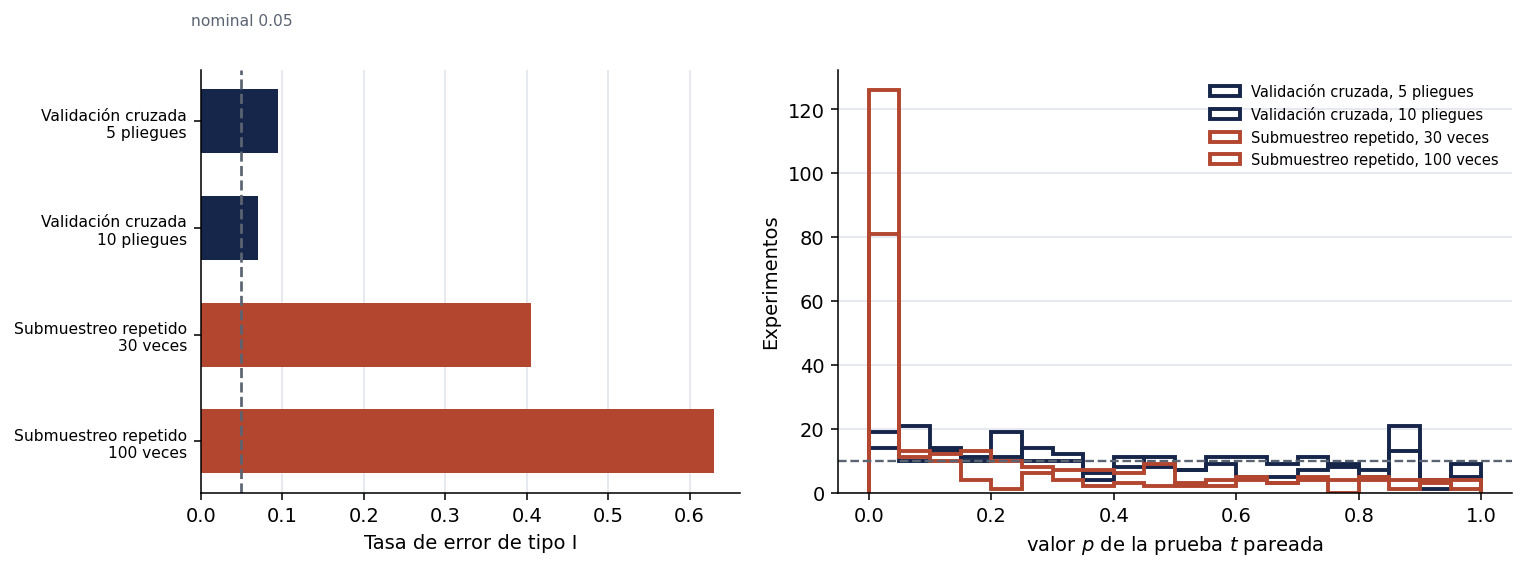

In [4]:
#| label: fig-tipoI
#| fig-cap: "Tasa de error de tipo I de la prueba t pareada, con la hipótesis nula verdadera."
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2), dpi=140,
                             gridspec_kw={"width_ratios": [1, 1.25]})

nombres_esq = list(tasas)
valores = [tasas[k] for k in nombres_esq]
colores = ["#16264A", "#16264A", "#B3462F", "#B3462F"]
a1.barh(range(len(valores)), valores, color=colores, height=0.6)
a1.axvline(ALFA, color="#5B6472", ls="--", lw=1.4)
a1.text(ALFA, -0.9, f"nominal {ALFA}", fontsize=8, color="#5B6472", ha="center")
a1.set_yticks(range(len(valores)))
a1.set_yticklabels([n.replace(", ", "\n") for n in nombres_esq], fontsize=8)
a1.invert_yaxis()
a1.set_xlabel("Tasa de error de tipo I")
a1.spines[["top", "right"]].set_visible(False)
a1.grid(axis="x", color="#E6EAF0", lw=1); a1.set_axisbelow(True)

for nombre, color in zip(nombres_esq, colores):
    a2.hist(valores_p[nombre], bins=np.linspace(0, 1, 21), histtype="step",
            lw=2, color=color, label=nombre)
a2.axhline(len(valores_p[nombres_esq[0]]) / 20, color="#5B6472", ls="--", lw=1.2)
a2.set_xlabel("valor $p$ de la prueba $t$ pareada")
a2.set_ylabel("Experimentos")
a2.spines[["top", "right"]].set_visible(False)
a2.grid(axis="y", color="#E6EAF0", lw=1); a2.set_axisbelow(True)
a2.legend(frameon=False, fontsize=7.5, loc="upper right")

fig.tight_layout()
fig.savefig("tasa_error_tipo_I.png", dpi=200, bbox_inches="tight")
plt.show()

Bajo una hipótesis nula verdadera y con una prueba válida, los valores $p$ se
distribuyen **uniformemente** entre 0 y 1: la línea discontinua del panel
derecho. Los dos esquemas de validación cruzada se acercan; los dos de
submuestreo repetido se amontonan contra el cero.

## 3. Experimento 2 — El procedimiento de Demšar

Ahora la pregunta 2 de la clase: comparar **cuatro algoritmos** sobre **18
conjuntos de datos** con protocolo idéntico.

Los conjuntos se generan con características distintas —número de casos,
atributos, informatividad y separación— para que la población de problemas sea
heterogénea, que es lo que hace interesante la pregunta.

In [5]:
rng = np.random.default_rng(SEMILLA + 7)

algoritmos = {
    "Logística":   lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "k-NN":        lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
    "Bosque":      lambda: RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1),
    "Potenciación": lambda: GradientBoostingClassifier(random_state=0),
}

desempenos = np.empty((N_CONJUNTOS, len(algoritmos)))
descripcion = []

for i in range(N_CONJUNTOS):
    n = int(rng.integers(200, 600))
    p = int(rng.integers(8, 30))
    inf = max(3, int(p * rng.uniform(0.2, 0.6)))
    sep = float(rng.uniform(0.6, 1.6))
    X, y = make_classification(n_samples=n, n_features=p, n_informative=inf,
                               n_redundant=max(0, p // 6), class_sep=sep,
                               random_state=int(rng.integers(0, 10**6)))
    descripcion.append((n, p, inf, round(sep, 2)))
    # MISMO protocolo para los cuatro: mismos pliegues, mismas semillas.
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
    for j, (nombre, construye) in enumerate(algoritmos.items()):
        desempenos[i, j] = cross_val_score(construye(), X, y, cv=cv,
                                           scoring="roc_auc").mean()

nombres = list(algoritmos)
print(f"{'conjunto':>9} {'n':>5} {'p':>4} " + "".join(f"{k:>14}" for k in nombres))
print("-" * (19 + 14 * len(nombres)))
for i in range(min(6, N_CONJUNTOS)):
    n, p, inf, sep = descripcion[i]
    print(f"{i+1:>9} {n:>5} {p:>4} " + "".join(f"{desempenos[i,j]:>14.3f}"
                                               for j in range(len(nombres))))
print(f"{'...':>9}")

 conjunto     n    p      Logística          k-NN        Bosque  Potenciación
---------------------------------------------------------------------------
        1   299   18          0.818         0.921         0.963         0.968
        2   453   10          0.986         0.970         0.981         0.981
        3   480   18          0.942         0.939         0.967         0.962
        4   254   10          0.966         0.914         0.979         0.967
        5   339   16          0.857         0.831         0.893         0.856
        6   362   27          0.873         0.957         0.945         0.923
      ...


## 4. Rangos, no valores

Como dice la clase, **promediar AUC entre conjuntos distintos no significa
nada**: un 0,72 en un problema difícil puede ser mejor que un 0,95 en uno fácil.
Se reemplaza cada fila por los rangos dentro de esa fila.

In [6]:
# Rango 1 = mejor. Se niega el desempeño porque rankdata ordena de menor a mayor.
rangos = np.array([stats.rankdata(-fila) for fila in desempenos])
rango_medio = rangos.mean(axis=0)

print(f"{'algoritmo':>14} {'AUC medio':>11} {'rango medio':>13}")
print("-" * 40)
for j in np.argsort(rango_medio):
    print(f"{nombres[j]:>14} {desempenos[:, j].mean():>11.3f} {rango_medio[j]:>13.2f}")

     algoritmo   AUC medio   rango medio
----------------------------------------
        Bosque       0.939          1.28
  Potenciación       0.929          2.33
          k-NN       0.909          3.06
     Logística       0.889          3.33


## 5. Friedman, y solo si se rechaza, la prueba posterior

In [7]:
est, p_friedman = stats.friedmanchisquare(*[desempenos[:, j] for j in range(len(nombres))])
print(f"Friedman:  chi2 = {est:.3f}   p = {p_friedman:.2e}")

if p_friedman >= ALFA:
    print("\nNo se rechaza la nula: NO se buscan pares. El análisis termina aquí.")
else:
    print("\nSe rechaza: procede la prueba posterior por pares.\n")
    pares = list(itertools.combinations(range(len(nombres)), 2))
    ps = [stats.wilcoxon(desempenos[:, a], desempenos[:, b]).pvalue for a, b in pares]

    # Corrección de Holm: uniformemente más potente que Bonferroni, misma garantía.
    orden = np.argsort(ps)
    m = len(ps)
    ajustados = np.empty(m)
    maximo = 0.0
    for k, idx in enumerate(orden):
        val = (m - k) * ps[idx]
        maximo = max(maximo, val)
        ajustados[idx] = min(1.0, maximo)

    print(f"{'par':>26} {'p crudo':>10} {'p (Holm)':>11}  significativo")
    print("-" * 66)
    for (a, b), pc, pa in zip(pares, ps, ajustados):
        print(f"{nombres[a] + ' vs ' + nombres[b]:>26} {pc:>10.4f} {pa:>11.4f}"
              f"{'   sí' if pa < ALFA else '   no':>16}")

Friedman:  chi2 = 27.267   p = 5.18e-06

Se rechaza: procede la prueba posterior por pares.

                       par    p crudo    p (Holm)  significativo
------------------------------------------------------------------
         Logística vs k-NN     0.1415      0.1415              no
       Logística vs Bosque     0.0000      0.0002              sí
 Logística vs Potenciación     0.0028      0.0084              sí
            k-NN vs Bosque     0.0003      0.0013              sí
      k-NN vs Potenciación     0.0077      0.0154              sí
    Bosque vs Potenciación     0.0003      0.0013              sí


## 6. El diagrama de diferencia crítica

Diferencia crítica de Nemenyi (k=4, N=18, alfa=0.05): 1.106


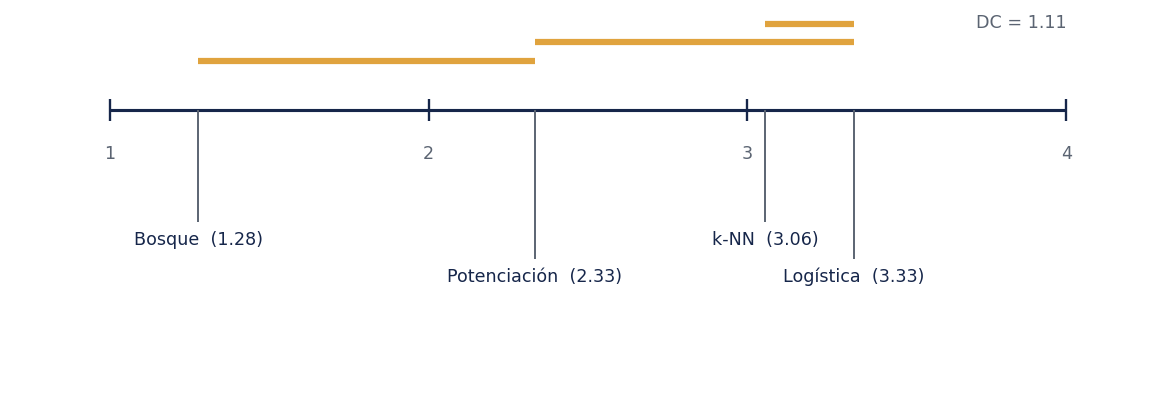

In [8]:
#| label: fig-diferencia-critica
#| fig-cap: "Rangos medios y diferencia crítica de Nemenyi sobre 18 conjuntos de datos."
k, N = len(nombres), N_CONJUNTOS
# Valor crítico del rango studentizado dividido por raíz de 2, alfa = 0,05.
Q_ALFA = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850}
dc = Q_ALFA[k] * np.sqrt(k * (k + 1) / (6 * N))
print(f"Diferencia crítica de Nemenyi (k={k}, N={N}, alfa={ALFA}): {dc:.3f}")

orden = np.argsort(rango_medio)
fig, ax = plt.subplots(figsize=(8.5, 3.0), dpi=140)
ax.set_xlim(0.7, k + 0.3); ax.set_ylim(0, 1)
ax.hlines(0.75, 1, k, color="#16264A", lw=1.6)
for x in range(1, k + 1):
    ax.vlines(x, 0.72, 0.78, color="#16264A", lw=1.2)
    ax.text(x, 0.62, str(x), ha="center", fontsize=9, color="#5B6472")

for rango_pos, j in enumerate(orden):
    r = rango_medio[j]
    alto = 0.45 - 0.10 * (rango_pos % 2)
    ax.vlines(r, alto, 0.75, color="#5B6472", lw=1)
    ax.text(r, alto - 0.06, f"{nombres[j]}  ({r:.2f})", ha="center",
            fontsize=9, color="#16264A")

# Barras que unen los grupos indistinguibles.
y_barra = 0.88
for i in range(k):
    j0 = orden[i]
    compañeros = [orden[t] for t in range(i, k)
                  if rango_medio[orden[t]] - rango_medio[j0] <= dc]
    if len(compañeros) > 1:
        ax.hlines(y_barra, rango_medio[j0], rango_medio[compañeros[-1]],
                  color="#E0A33E", lw=3.2)
        y_barra += 0.05

ax.text(k, 0.97, f"DC = {dc:.2f}", ha="right", fontsize=9, color="#5B6472")
ax.axis("off")
fig.tight_layout()
fig.savefig("diagrama_diferencia_critica.png", dpi=200, bbox_inches="tight")
plt.show()

Los algoritmos se sitúan en la recta por su **rango medio** —mejor a la
izquierda—, y las barras ámbar unen los que **no se distinguen** con estos datos.

Dos advertencias sobre cómo se lee:

- Una barra que une dos algoritmos significa «no se distinguen con estos 18
  conjuntos», **no** «son equivalentes». Ausencia de evidencia no es evidencia de
  ausencia.
- La diferencia crítica depende de $N$: con más conjuntos de datos se estrecha, y
  diferencias que aquí no se distinguen podrían distinguirse.

## 7. El tamaño del efecto

Un valor $p$ dice si la diferencia es distinguible del ruido. **No dice si
importa.** Para eso hay que mirar la magnitud en las unidades del problema.

In [9]:
mejor, peor = orden[0], orden[-1]
dif = desempenos[:, mejor] - desempenos[:, peor]
q1, q3 = np.percentile(dif, [25, 75])

print(f"Diferencia de AUC entre {nombres[mejor]} y {nombres[peor]}:")
print(f"  mediana:                 {np.median(dif):+.4f}")
print(f"  rango intercuartílico:   [{q1:+.4f}, {q3:+.4f}]")
print(f"  conjuntos en que gana:   {int((dif > 0).sum())} de {N_CONJUNTOS}")
print()
print("Y la pregunta que ninguna prueba responde:")
print("  ¿cambia esa magnitud alguna decisión en su problema?")

Diferencia de AUC entre Bosque y Logística:
  mediana:                 +0.0355
  rango intercuartílico:   [+0.0133, +0.0764]
  conjuntos en que gana:   17 de 18

Y la pregunta que ninguna prueba responde:
  ¿cambia esa magnitud alguna decisión en su problema?


## 8. Bitácora

**Decisiones tomadas**

1. *Datos sin señal en el experimento 1.* Es lo que lo hace concluyente: la
   hipótesis nula es **verdadera por construcción**, así que toda tasa de rechazo
   por encima del 5 % es un defecto de la prueba y no un hallazgo. Una primera
   versión comparaba dos bosques que solo diferían en la semilla, y no mostraba
   nada: dos modelos casi idénticos producen diferencias casi nulas, y la prueba
   apenas rechazaba. El diseño correcto exige algoritmos **distintos** cuyo
   desempeño esperado sea **igual**, y eso se consigue quitando la señal.
2. *Cuatro esquemas de remuestreo, no uno.* Comparar validación cruzada con
   submuestreo repetido es lo que revela el hallazgo: el problema no está en
   «remuestrear» sino en **cuánto se reutilizan los mismos casos**.
3. *200 experimentos.* El error estándar de una proporción cercana a 0,05 es de
   unos 0,015, suficiente para distinguir el nivel nominal de una inflación de
   varias veces.
4. *18 conjuntos de datos.* Demšar recomienda al menos 10, y con menos la
   diferencia crítica de Nemenyi es tan ancha que nada resulta distinguible.
5. *Conjuntos heterogéneos.* Tamaño, dimensión, informatividad y separación se
   sortean. Con conjuntos homogéneos, la comparación mediría un solo problema
   repetido y la pregunta 2 de la clase perdería sentido.
6. *Protocolo idéntico para los cuatro algoritmos*, con los mismos pliegues y las
   mismas semillas. Es lo que exige la lámina «El presupuesto».
7. *Holm y no Bonferroni.* Misma garantía sobre la tasa de error familiar y
   uniformemente más potencia. No hay razón para preferir Bonferroni.
8. *Rangos y no promedios de AUC.* Promediar AUC entre conjuntos de dificultad
   distinta no tiene interpretación.

**Decisión alternativa descartada** — ítem 7 de la lista de cotejo

Se consideró ajustar los hiperparámetros de cada algoritmo por validación
anidada antes de comparar, que es lo correcto en un estudio metodológico serio.
**Se descartó** por costo: la validación anidada sobre 4 algoritmos, 18 conjuntos
y una rejilla razonable multiplica el tiempo de ejecución por más de cien, y el
cuaderno dejaría de poder ejecutarse en clase. La consecuencia hay que declararla
y no esconderla: **esta comparación usa hiperparámetros por defecto**, de modo
que mide los algoritmos tal como vienen y no en su mejor versión. Eso favorece
sistemáticamente a los métodos cuyos valores por defecto son buenos, y es
exactamente el tipo de sesgo que Grinsztajn et al. denuncian. En un trabajo
publicable habría que hacer la validación anidada.

**Uso de asistentes de IA**

Declarar aquí en qué parte del trabajo se usaron, según la regla operativa del
módulo.

## 9. Verificación

In [10]:
# 1. Con la nula verdadera, la validación cruzada se acerca al nivel nominal
#    y el submuestreo repetido se dispara.
t_vc  = tasas["Validación cruzada, 10 pliegues"]
t_sub = tasas["Submuestreo repetido, 100 veces"]
assert t_vc < 3 * ALFA,  "La VC no debería inflar tanto."
assert t_sub > 5 * ALFA, "El submuestreo repetido debería inflar de forma grosera."
assert tasas["Submuestreo repetido, 100 veces"] > tasas["Submuestreo repetido, 30 veces"], \
    "Más remuestreos deberían empeorar el problema, no mejorarlo."

# 2. El procedimiento de Demšar produce un orden y una diferencia crítica coherentes.
assert rangos.shape == (N_CONJUNTOS, len(nombres))
assert np.allclose(rangos.sum(axis=1), len(nombres) * (len(nombres) + 1) / 2), \
    "Los rangos de cada fila deben sumar k(k+1)/2."
assert 0 < dc < len(nombres), "La diferencia crítica debe ser un valor razonable."

# 3. El mejor por rango medio también gana en la mayoría de los conjuntos.
assert (desempenos[:, orden[0]] > desempenos[:, orden[-1]]).sum() > N_CONJUNTOS / 2

print("Verificado:")
print(f"  - tasa de error tipo I: VC 10 pliegues {t_vc:.3f}, "
      f"submuestreo x100 {t_sub:.3f}  (nominal {ALFA});")
print(f"  - más remuestreos empeoran: "
      f"{tasas['Submuestreo repetido, 30 veces']:.3f} -> {t_sub:.3f};")
print(f"  - los rangos de cada fila suman {len(nombres)*(len(nombres)+1)//2};")
print(f"  - diferencia crítica de Nemenyi = {dc:.3f};")
print(f"  - Friedman p = {p_friedman:.2e};")
print(f"  - mejor rango medio: {nombres[orden[0]]} ({rango_medio[orden[0]]:.2f}).")

Verificado:
  - tasa de error tipo I: VC 10 pliegues 0.070, submuestreo x100 0.630  (nominal 0.05);
  - más remuestreos empeoran: 0.405 -> 0.630;
  - los rangos de cada fila suman 10;
  - diferencia crítica de Nemenyi = 1.106;
  - Friedman p = 5.18e-06;
  - mejor rango medio: Bosque (1.28).
